# 05 — Variable Selection

Evaluate candidate predictors for the cross-sectional analysis using economic reasoning and the assignment requirements. Document the rationale for the variables and specifications you choose.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv"
)

print("Original observations:", len(parking))

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()

print("Observations after excluding JUMP:", len(parking))


Original observations: 4139
Observations after excluding JUMP: 4060


In [2]:

variables = [
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "median_income",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "RateType",
    "MeterType",
    "housing_density",
    "transit_share",
    "walk_share",
    "nearby_business_count"
]

y = parking["occupancy_rate"]

X = parking[variables].copy()

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Explanatory variables:", X.columns.tolist())
print("Number of explanatory variables:", X.shape[1])


Explanatory variables: ['price_midpoint', 'time_limit_hours', 'population_density', 'median_income', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD', 'MeterType_Single-Space']
Number of explanatory variables: 12


In [3]:

data = pd.concat([y, X], axis=1)

print("Missing values:")
print(data.isnull().sum())

data = data.dropna()

y = data["occupancy_rate"]
X = data.drop(columns="occupancy_rate")

print("Final observations:", len(data))
print("Number of predictors:", X.shape[1])


Missing values:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
median_income                     44
nearby_restaurant_retail_count     0
drive_alone_share                  0
housing_density                    0
transit_share                      0
walk_share                         0
nearby_business_count              0
RateType_TOD                       0
MeterType_Single-Space             0
dtype: int64
Final observations: 4016
Number of predictors: 12


In [4]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X)

vif = pd.DataFrame()
vif["Variable"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.round(2)


,Variable,VIF
0,const,110.00
1,price_midpoint,1.71
2,time_limit_hours,1.16
3,population_density,11.98
4,median_income,2.08
5,nearby_restaurant_retail_count,5.91
6,drive_alone_share,2.96
7,housing_density,12.69
8,transit_share,2.32
9,walk_share,3.03


In [5]:

X_reduced = X.drop(columns=[
    "housing_density",
    "nearby_business_count"
])

X_vif_reduced = sm.add_constant(X_reduced)

vif_reduced = pd.DataFrame({
    "Variable": X_vif_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_vif_reduced.values, i)
        for i in range(X_vif_reduced.shape[1])
    ]
})

vif_reduced.round(2)


,Variable,VIF
0,const,109.12
1,price_midpoint,1.64
2,time_limit_hours,1.13
3,population_density,1.18
4,median_income,2.03
5,nearby_restaurant_retail_count,1.75
6,drive_alone_share,2.79
7,transit_share,2.27
8,walk_share,2.49
9,RateType_TOD,1.23


In [6]:

%pip install boruta


Note: you may need to restart the kernel to use updated packages.


In [9]:

from boruta import BorutaPy
from sklearn.ensemble import RandomForestRegressor

# Prepare data
parking_Y = y.values
parking_X = X.values.astype(np.float32)

# Random forest
rf = RandomForestRegressor(max_depth=5)

# Boruta
boruta = BorutaPy(
    rf,
    n_estimators="auto",
    verbose=2,
    random_state=10,
    two_step=True
)

boruta.fit(parking_X, parking_Y)

print("\nConfirmed:", list(X.columns[boruta.support_]))


Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	9 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	10 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	11 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	12 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	13 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	14 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	15 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	16 / 100
Confirmed: 	9
Tentative: 	2
Rejected: 	1
Iteration:

In [10]:

boruta_keep = [
    "Confirmed" if c else "Tentative" if t else "Reject"
    for c, t in zip(boruta.support_, boruta.support_weak_)
]

boruta_features = zip(
    X.columns,
    boruta.ranking_,
    boruta_keep
)

for feat in boruta_features:
    print("Feature: {:<35} Rank: {}, Keep: {}".format(
        feat[0], feat[1], feat[2]
    ))


Feature: price_midpoint                      Rank: 1, Keep: Confirmed
Feature: time_limit_hours                    Rank: 1, Keep: Confirmed
Feature: population_density                  Rank: 1, Keep: Confirmed
Feature: median_income                       Rank: 2, Keep: Reject
Feature: nearby_restaurant_retail_count      Rank: 1, Keep: Confirmed
Feature: drive_alone_share                   Rank: 1, Keep: Confirmed
Feature: housing_density                     Rank: 1, Keep: Confirmed
Feature: transit_share                       Rank: 1, Keep: Confirmed
Feature: walk_share                          Rank: 1, Keep: Confirmed
Feature: nearby_business_count               Rank: 1, Keep: Confirmed
Feature: RateType_TOD                        Rank: 1, Keep: Confirmed
Feature: MeterType_Single-Space              Rank: 3, Keep: Reject


In [11]:

full_model = sm.OLS(y, sm.add_constant(X)).fit()

print(full_model.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     140.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          8.50e-295
Time:                        20:24:24   Log-Likelihood:                 1608.0
No. Observations:                4016   AIC:                            -3190.
Df Residuals:                    4003   BIC:                            -3108.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

In [12]:

from itertools import combinations

sigma2 = full_model.mse_resid

cp_results = []

for k in range(1, len(X.columns) + 1):
    for cols in combinations(X.columns, k):
        model = sm.OLS(y, sm.add_constant(X[list(cols)])).fit()

        rss = sum(model.resid ** 2)
        p = k + 1

        cp = rss / sigma2 - (len(y) - 2 * p)

        cp_results.append({
            "Variables": cols,
            "Number of predictors": k,
            "Cp": cp,
            "Adjusted R2": model.rsquared_adj
        })

cp_results = pd.DataFrame(cp_results)

cp_results.sort_values("Cp").head(10)


,Variables,Number of predictors,Cp,Adjusted R2
4050,"(price_midpoint, time_limit_hours, population_...",10,9.949599,0.294709
3950,"(price_midpoint, population_density, nearby_re...",9,10.531400,0.294431
4090,"(price_midpoint, time_limit_hours, population_...",11,11.122981,0.294679
4069,"(price_midpoint, population_density, nearby_re...",10,11.578361,0.294423
4088,"(price_midpoint, time_limit_hours, population_...",11,11.773507,0.294564
3582,"(price_midpoint, population_density, nearby_re...",8,11.788981,0.294033
3867,"(price_midpoint, time_limit_hours, population_...",9,11.923251,0.294186
4067,"(price_midpoint, population_density, median_in...",10,12.257728,0.294303
3944,"(price_midpoint, population_density, nearby_re...",9,12.613759,0.294064
4044,"(price_midpoint, time_limit_hours, population_...",10,12.845720,0.294199


In [13]:

best_cp = cp_results.loc[
    cp_results.groupby("Number of predictors")["Cp"].idxmin()
]

best_cp[["Number of predictors", "Cp", "Adjusted R2"]].round(3)


,Number of predictors,Cp,Adjusted R2
0,1,786.957,0.157
13,2,413.784,0.222
93,3,231.578,0.255
414,4,82.641,0.281
956,5,55.239,0.286
1882,6,20.214,0.292
2861,7,17.199,0.293
3582,8,11.789,0.294
3950,9,10.531,0.294
4050,10,9.950,0.295


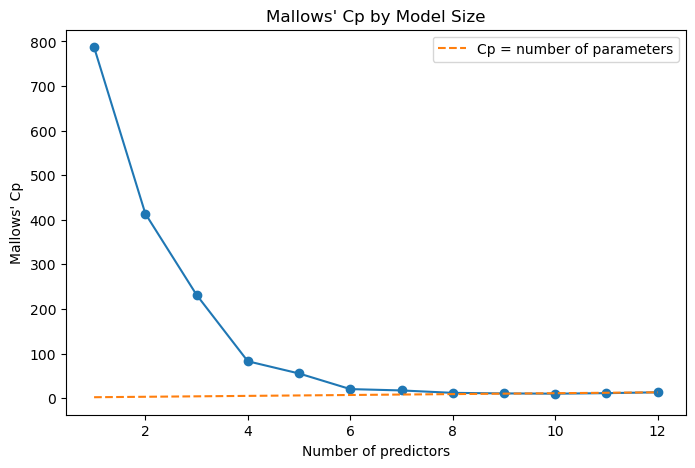

In [14]:

plt.figure(figsize=(8, 5))

plt.plot(
    best_cp["Number of predictors"],
    best_cp["Cp"],
    marker="o"
)

plt.plot(
    best_cp["Number of predictors"],
    best_cp["Number of predictors"] + 1,
    linestyle="--",
    label="Cp = number of parameters"
)

plt.xlabel("Number of predictors")
plt.ylabel("Mallows' Cp")
plt.title("Mallows' Cp by Model Size")
plt.legend()
plt.show()


In [15]:

best_8 = cp_results[
    cp_results["Number of predictors"] == 8
].sort_values("Cp").iloc[0]

print("Best 8-variable model:")
for variable in best_8["Variables"]:
    print(variable)

print("\nMallows' Cp:", round(best_8["Cp"], 3))
print("Adjusted R2:", round(best_8["Adjusted R2"], 3))


Best 8-variable model:
price_midpoint
population_density
nearby_restaurant_retail_count
housing_density
transit_share
walk_share
nearby_business_count
RateType_TOD

Mallows' Cp: 11.789
Adjusted R2: 0.294


In [16]:

best_8 = cp_results[
    cp_results["Number of predictors"] == 8
].sort_values("Cp").iloc[0]

print("Best 8-variable model:")
for variable in best_8["Variables"]:
    print(variable)

print("\nMallows' Cp:", round(best_8["Cp"], 3))
print("Adjusted R2:", round(best_8["Adjusted R2"], 3))


Best 8-variable model:
price_midpoint
population_density
nearby_restaurant_retail_count
housing_density
transit_share
walk_share
nearby_business_count
RateType_TOD

Mallows' Cp: 11.789
Adjusted R2: 0.294


In [17]:

comparison = pd.DataFrame({
    "Variable": X.columns,
    "Boruta Selected": boruta.support_,
    "Mallows Cp (8)": X.columns.isin(best_8["Variables"])
})

comparison = comparison.merge(
    vif[["Variable", "VIF"]],
    on="Variable",
    how="left"
)

comparison.round(2)


,Variable,Boruta Selected,Mallows Cp (8),VIF
0,price_midpoint,True,True,1.71
1,time_limit_hours,True,False,1.16
2,population_density,True,True,11.98
3,median_income,False,False,2.08
4,nearby_restaurant_retail_count,True,True,5.91
5,drive_alone_share,True,False,2.96
6,housing_density,True,True,12.69
7,transit_share,True,True,2.32
8,walk_share,True,True,3.03
9,nearby_business_count,True,True,6.68


In [18]:

selected_variables = [
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "transit_share",
    "RateType_TOD"
]

X_selected = X[selected_variables]

X_selected_vif = sm.add_constant(X_selected)

selected_vif = pd.DataFrame({
    "Variable": X_selected_vif.columns,
    "VIF": [
        variance_inflation_factor(X_selected_vif.values, i)
        for i in range(X_selected_vif.shape[1])
    ]
})

selected_vif.round(2)


,Variable,VIF
0,const,36.83
1,price_midpoint,1.62
2,time_limit_hours,1.11
3,population_density,1.09
4,nearby_restaurant_retail_count,1.67
5,drive_alone_share,1.67
6,transit_share,1.25
7,RateType_TOD,1.18


### Variable Selection Summary

I compared 12 candidate explanatory variables using VIF, Boruta, and Mallows' Cp.

Boruta confirmed 10 variables and rejected median income and meter type. Mallows' Cp showed that models with approximately 8–10 predictors provided similar adjusted R² values.

The initial VIF results showed substantial multicollinearity between population and housing density, as well as overlap between the two business-count variables. I retained population density and restaurant/retail count because they are directly relevant to parking demand.

My preferred specification contains seven explanatory variables: price, time limit, population density, restaurant/retail count, drive-alone commuting share, transit commuting share, and the TOD pricing indicator.

All seven predictors have VIF values below 2. I will use this specification as the main model and compare it with simpler OLS models in Notebook 06. These variables are associated with occupancy, but the analysis does not establish causal effects.